# 第5章：线性模型的解、复杂度和收缩

**学生实验｜全书深化稿**

## 背景与数据
三点OLS、相关特征和300条非线性响应均为人工演示。住房实际数据为单独下载的扩展，不被此处替代。

## 本次要回答的问题
核对OLS，比较多项式阶数和Ridge/Lasso单参数收缩，分析残差和验证表现。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 5: complete least squares and polynomial complexity examples."""
import numpy as np
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error,mean_absolute_error
from common import *

def run():
    x=np.array([1.,2.,3.]);y=np.array([2.,3.,5.]);D=np.column_stack([np.ones(3),x])
    beta=np.linalg.lstsq(D,y,rcond=None)[0]
    assert np.allclose(beta,[1/3,1.5])
    assert np.allclose(D.T@(D@beta-y),0,atol=1e-12)
    table('ch05_hand',{'x':x,'y':y,'prediction':D@beta,'residual_y_minus_pred':y-D@beta})
    tr,va,_=regression_demo();rows=[]
    for degree in [1,2,3,5,9,15]:
        m=make_pipeline(PolynomialFeatures(degree,include_bias=False),StandardScaler(),Ridge(alpha=1e-6))
        m.fit(tr[['x']],tr.target)
        rows.append({'degree':degree,'train_RMSE':np.sqrt(mean_squared_error(tr.target,m.predict(tr[['x']]))),
                     'validation_RMSE':np.sqrt(mean_squared_error(va.target,m.predict(va[['x']])) )})
    df=table('ch05_polynomial',rows);show_result(df)
    plt.figure(figsize=(6.4,4));plt.plot(df.degree,df.train_RMSE,'o-',label='training');plt.plot(df.degree,df.validation_RMSE,'s-',label='validation')
    plt.xlabel('多项式次数');plt.ylabel('RMSE（人工单位）');plt.legend();figure('v3_ch05_degree')
    # Collinear features: coefficient interpretation is not prediction performance.
    rng=np.random.default_rng(5);a=rng.normal(size=100);Z=np.column_stack([a,a+rng.normal(0,.01,100)])
    y2=2*a+rng.normal(0,.2,100);rows=[]
    for seed in range(12):
        ids=np.random.default_rng(seed).choice(len(a),len(a),replace=True)
        for name,m in [('OLS',LinearRegression()),('Ridge',Ridge(alpha=1.))]:
            m.fit(Z[ids],y2[ids]);rows.append({'method':name,'seed':seed,'b1':m.coef_[0],'b2':m.coef_[1],'sum':m.coef_.sum()})
    df=table('ch05_collinearity',rows)
    plt.figure(figsize=(6.4,4))
    for name in ['OLS','Ridge']:
        s=df[df.method==name];plt.scatter(s.b1,s.b2,label=name)
    plt.xlabel('第一个系数');plt.ylabel('第二个系数');plt.legend();figure('v3_ch05_collinearity')
    # One-dimensional normalized objective: J=(w-2)^2/2 + penalty.
    lam=np.array([0,.5,1,2,3]);out=table('ch05_shrinkage',{'lambda':lam,'ridge':2/(1+lam),'lasso':np.maximum(2-lam,0)})
    show_result(out)

In [3]:
result = run()
if result is not None:
    print(result)

 degree  train_RMSE  validation_RMSE
      1    0.653004         0.690422
      2    0.651988         0.692501
      3    0.623603         0.704613
      5    0.496488         0.495700
      9    0.358514         0.286192
     15    0.356209         0.292785


 lambda    ridge  lasso
    0.0 2.000000    2.0
    0.5 1.333333    1.5
    1.0 1.000000    1.0
    2.0 0.666667    0.0
    3.0 0.500000    0.0


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch05_collinearity.png


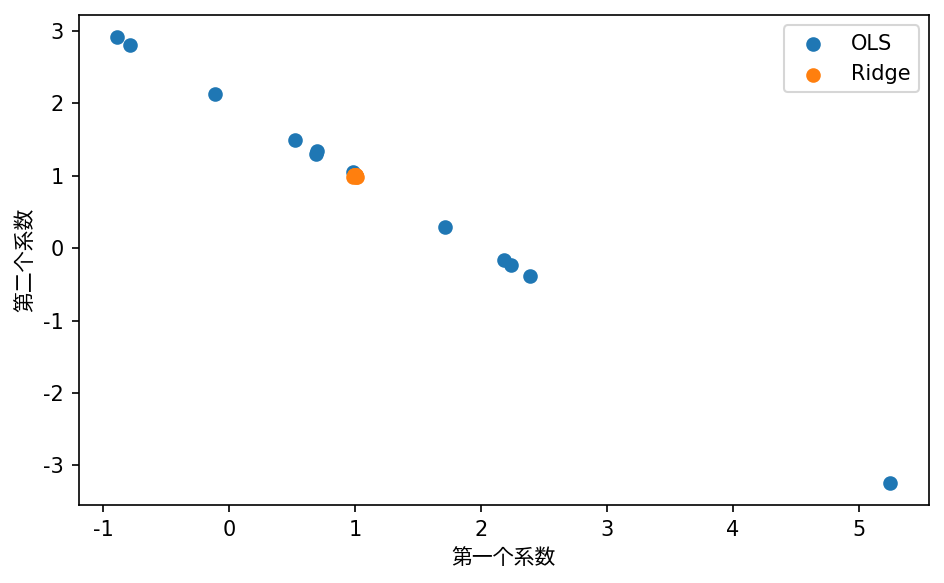

v3_ch05_degree.png


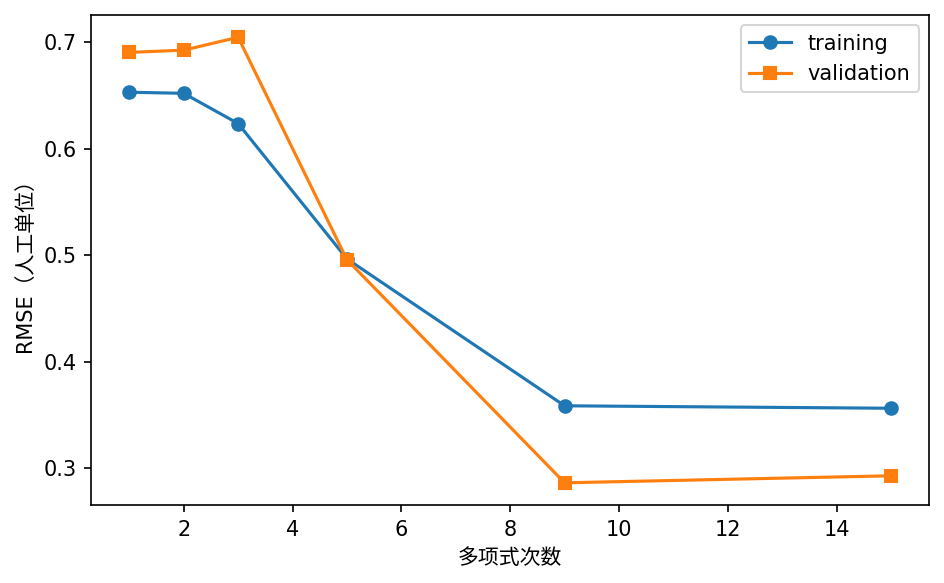

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch05_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

核对OLS，比较多项式阶数和Ridge/Lasso单参数收缩，分析残差和验证表现。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。